# 01 — Exploratory Data Analysis
**Ames Housing Dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
plt.rcParams.update({
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 120,
})

df = pd.read_csv('data/train.csv')
print(df.shape)

(1460, 81)


## 1. Overview

In [3]:
print('Shape:', df.shape)
print(f'Numeric features:     {df.select_dtypes(include="number").shape[1] - 1}')
print(f'Categorical features: {df.select_dtypes(include="object").shape[1]}')
df.head()

Shape: (1460, 81)
Numeric features:     37
Categorical features: 43


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
df['SalePrice'].describe().round(0)

count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

## 2. Target Variable — SalePrice

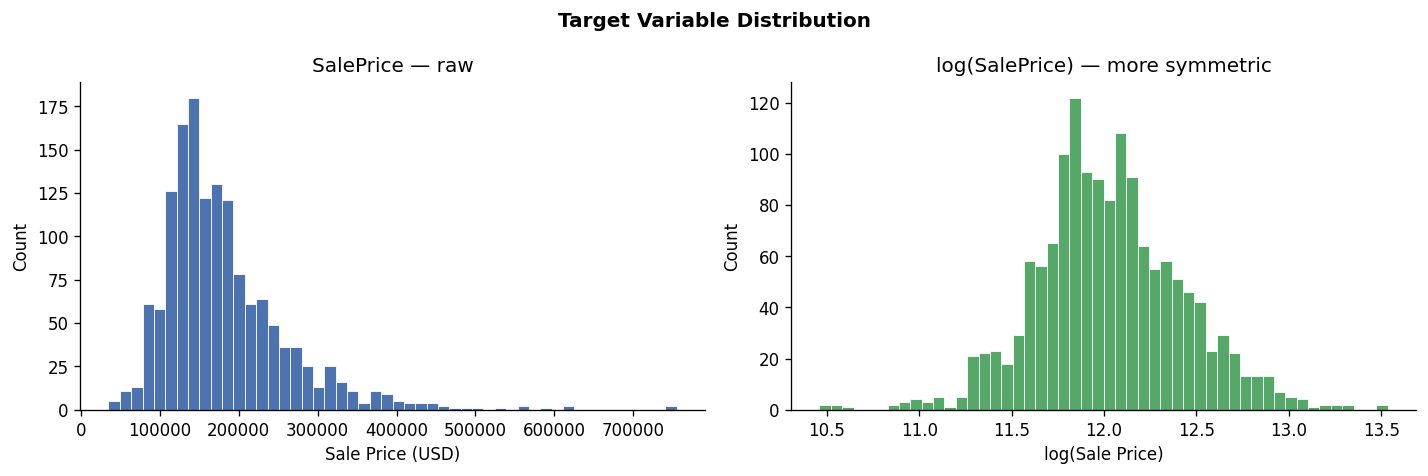

Skewness (raw):    1.883
Skewness (log):    0.121


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['SalePrice'], bins=50, color='#4C72B0', edgecolor='white', linewidth=0.5)
axes[0].set_title('SalePrice — raw')
axes[0].set_xlabel('Sale Price (USD)')
axes[0].set_ylabel('Count')

axes[1].hist(np.log1p(df['SalePrice']), bins=50, color='#55A868', edgecolor='white', linewidth=0.5)
axes[1].set_title('log(SalePrice) — more symmetric')
axes[1].set_xlabel('log(Sale Price)')
axes[1].set_ylabel('Count')

fig.suptitle('Target Variable Distribution', fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Skewness (raw):    {df["SalePrice"].skew():.3f}')
print(f'Skewness (log):    {np.log1p(df["SalePrice"]).skew():.3f}')

## 3. Missing Values

In [6]:
missing = df.isnull().sum()
missing = (missing[missing > 0] / len(df) * 100).sort_values(ascending=False)

print(f'{len(missing)} features have missing values\n')
print(missing.round(1).to_string())

19 features have missing values

PoolQC          99.5
MiscFeature     96.3
Alley           93.8
Fence           80.8
MasVnrType      59.7
FireplaceQu     47.3
LotFrontage     17.7
GarageType       5.5
GarageYrBlt      5.5
GarageFinish     5.5
GarageQual       5.5
GarageCond       5.5
BsmtExposure     2.6
BsmtFinType2     2.6
BsmtQual         2.5
BsmtCond         2.5
BsmtFinType1     2.5
MasVnrArea       0.5
Electrical       0.1


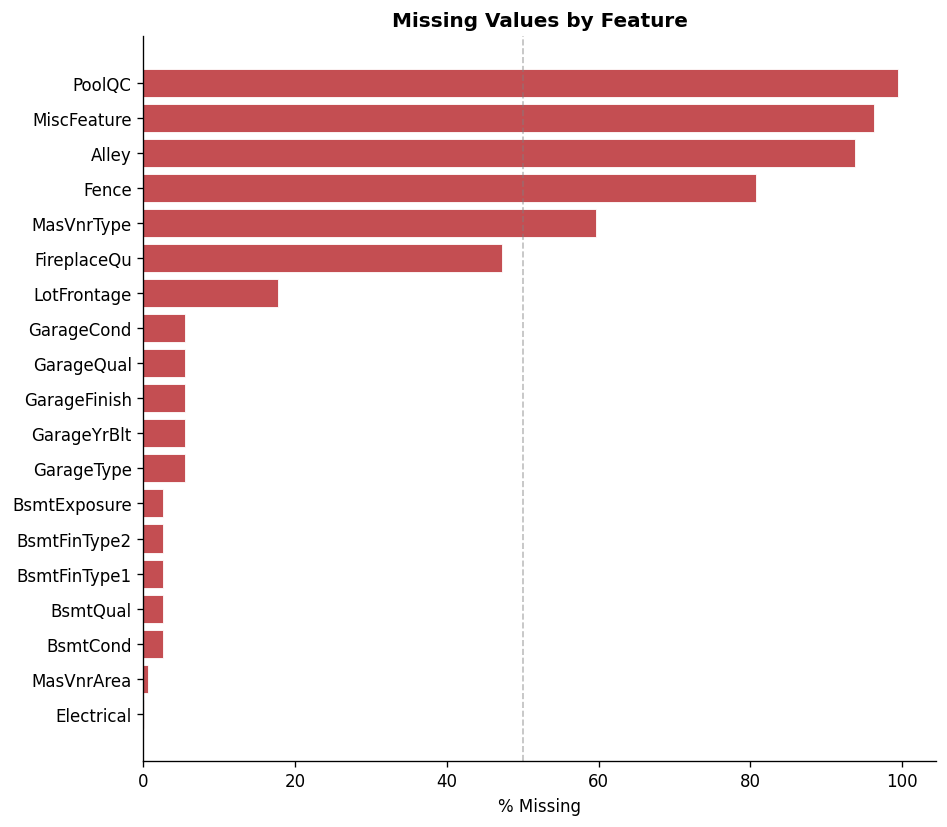

In [7]:
fig, ax = plt.subplots(figsize=(8, 7))
missing_sorted = missing.sort_values(ascending=True)
ax.barh(missing_sorted.index, missing_sorted.values, color='#C44E52', edgecolor='white', linewidth=0.5)
ax.set_xlabel('% Missing')
ax.set_title('Missing Values by Feature', fontweight='bold')
ax.axvline(50, color='gray', linestyle='--', alpha=0.5, linewidth=1)
plt.tight_layout()
plt.show()

## 4. Correlations with SalePrice

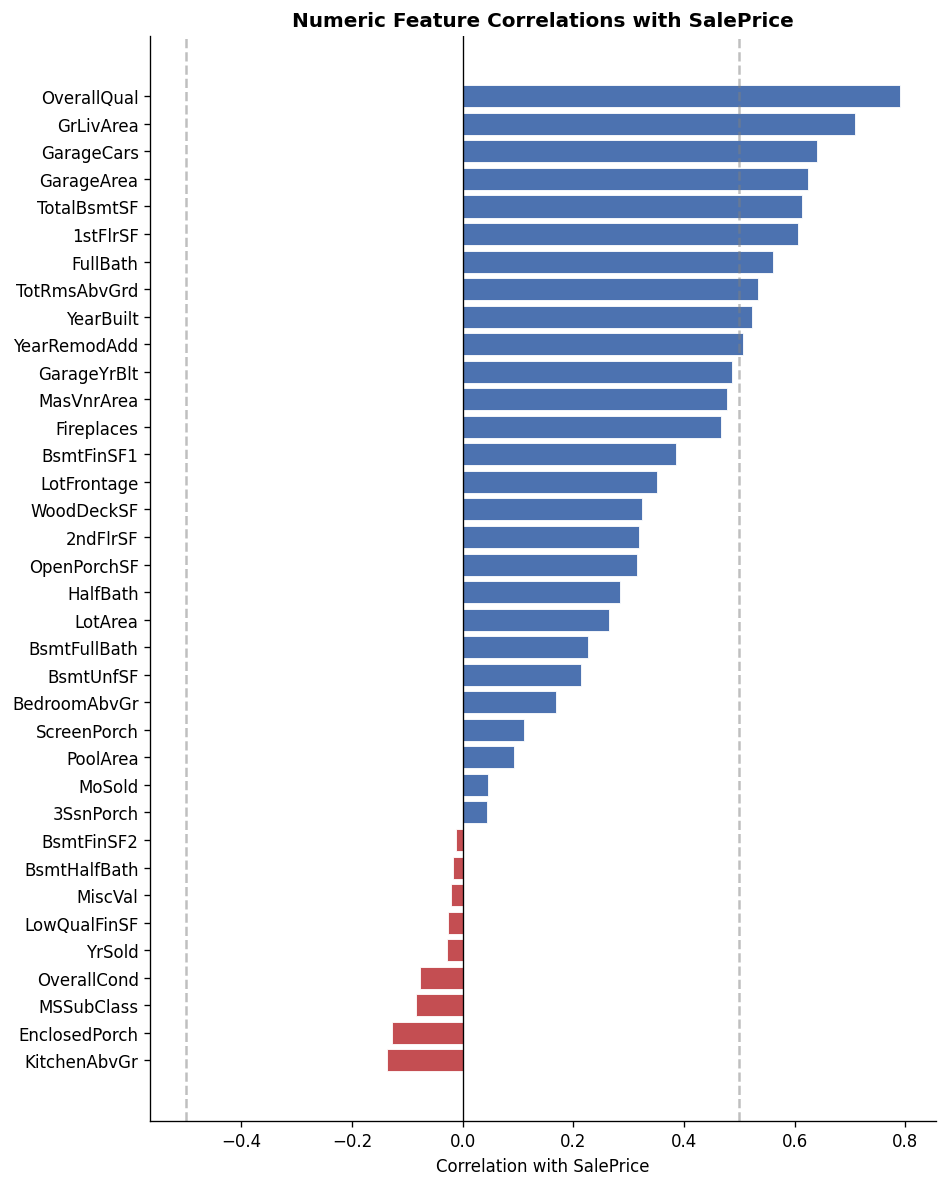

Top 10 positive:
YearRemodAdd    0.507
YearBuilt       0.523
TotRmsAbvGrd    0.534
FullBath        0.561
1stFlrSF        0.606
TotalBsmtSF     0.614
GarageArea      0.623
GarageCars      0.640
GrLivArea       0.709
OverallQual     0.791

Top negative:
KitchenAbvGr    -0.136
EnclosedPorch   -0.129
MSSubClass      -0.084
OverallCond     -0.078
YrSold          -0.029


In [8]:
num_cols = df.select_dtypes(include='number').drop(columns=['Id', 'SalePrice'])
corr = num_cols.corrwith(df['SalePrice']).sort_values()

fig, ax = plt.subplots(figsize=(8, 10))
colors = ['#C44E52' if v < 0 else '#4C72B0' for v in corr.values]
ax.barh(corr.index, corr.values, color=colors, edgecolor='white', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.8)
ax.axvline(0.5, color='gray', linestyle='--', alpha=0.5)
ax.axvline(-0.5, color='gray', linestyle='--', alpha=0.5)
ax.set_xlabel('Correlation with SalePrice')
ax.set_title('Numeric Feature Correlations with SalePrice', fontweight='bold')
plt.tight_layout()
plt.show()

print('Top 10 positive:')
print(corr.tail(10).round(3).to_string())
print('\nTop negative:')
print(corr.head(5).round(3).to_string())

## 5. Key Features vs SalePrice

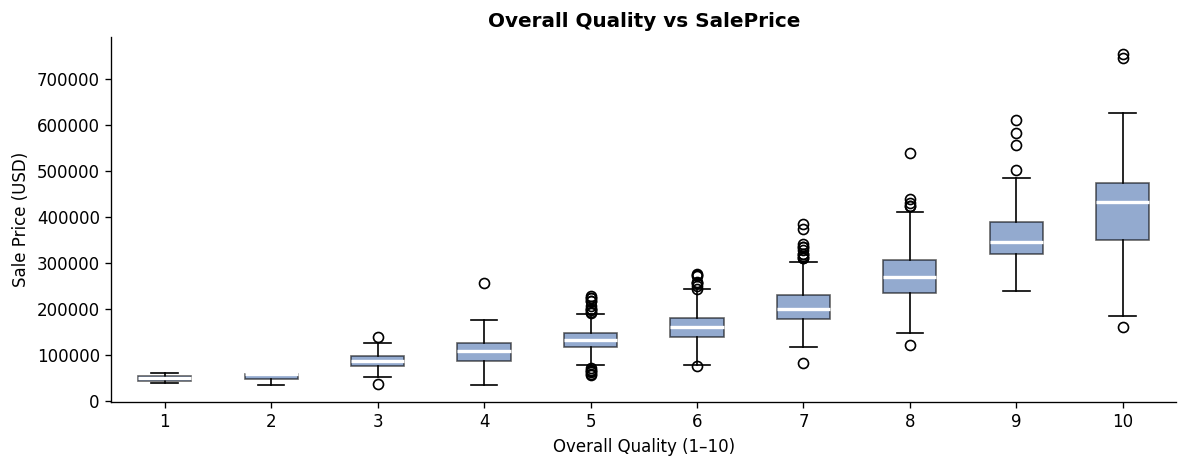

In [9]:
# Overall Quality — strongest single predictor
fig, ax = plt.subplots(figsize=(10, 4))
qual_groups = [df[df['OverallQual'] == q]['SalePrice'].values
               for q in sorted(df['OverallQual'].unique())]
ax.boxplot(qual_groups, labels=sorted(df['OverallQual'].unique()),
           patch_artist=True, boxprops=dict(facecolor='#4C72B0', alpha=0.6),
           medianprops=dict(color='white', linewidth=2))
ax.set_xlabel('Overall Quality (1–10)')
ax.set_ylabel('Sale Price (USD)')
ax.set_title('Overall Quality vs SalePrice', fontweight='bold')
plt.tight_layout()
plt.show()

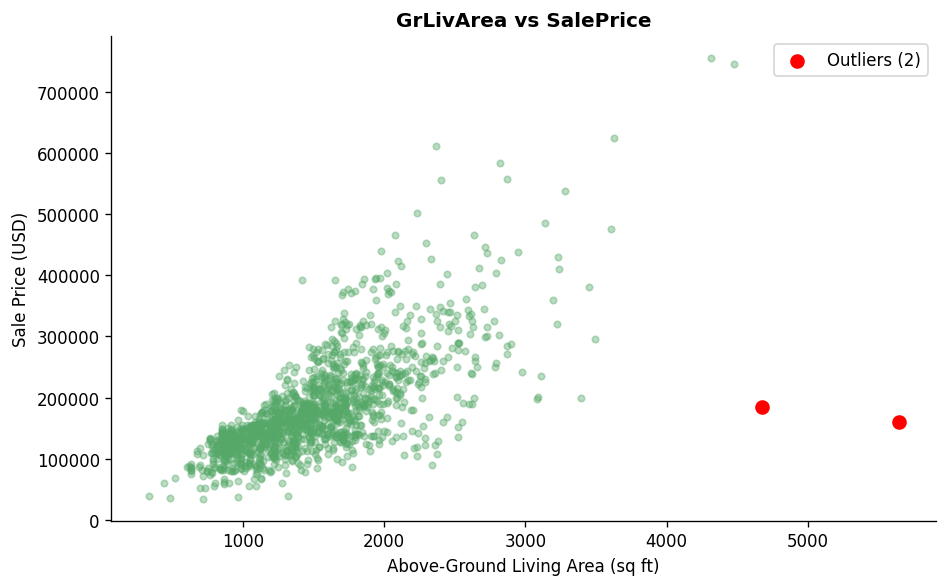

Potential outliers to review:
      GrLivArea  SalePrice  OverallQual Neighborhood
523        4676     184750           10      Edwards
1298       5642     160000           10      Edwards


In [10]:
# Living area vs price — look for outliers
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df['GrLivArea'], df['SalePrice'], alpha=0.4, s=15, color='#55A868')

# flag potential outliers
outliers = df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 200000)]
ax.scatter(outliers['GrLivArea'], outliers['SalePrice'], color='red', s=60, zorder=5, label=f'Outliers ({len(outliers)})')
ax.set_xlabel('Above-Ground Living Area (sq ft)')
ax.set_ylabel('Sale Price (USD)')
ax.set_title('GrLivArea vs SalePrice', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

if len(outliers) > 0:
    print('Potential outliers to review:')
    print(outliers[['GrLivArea', 'SalePrice', 'OverallQual', 'Neighborhood']])

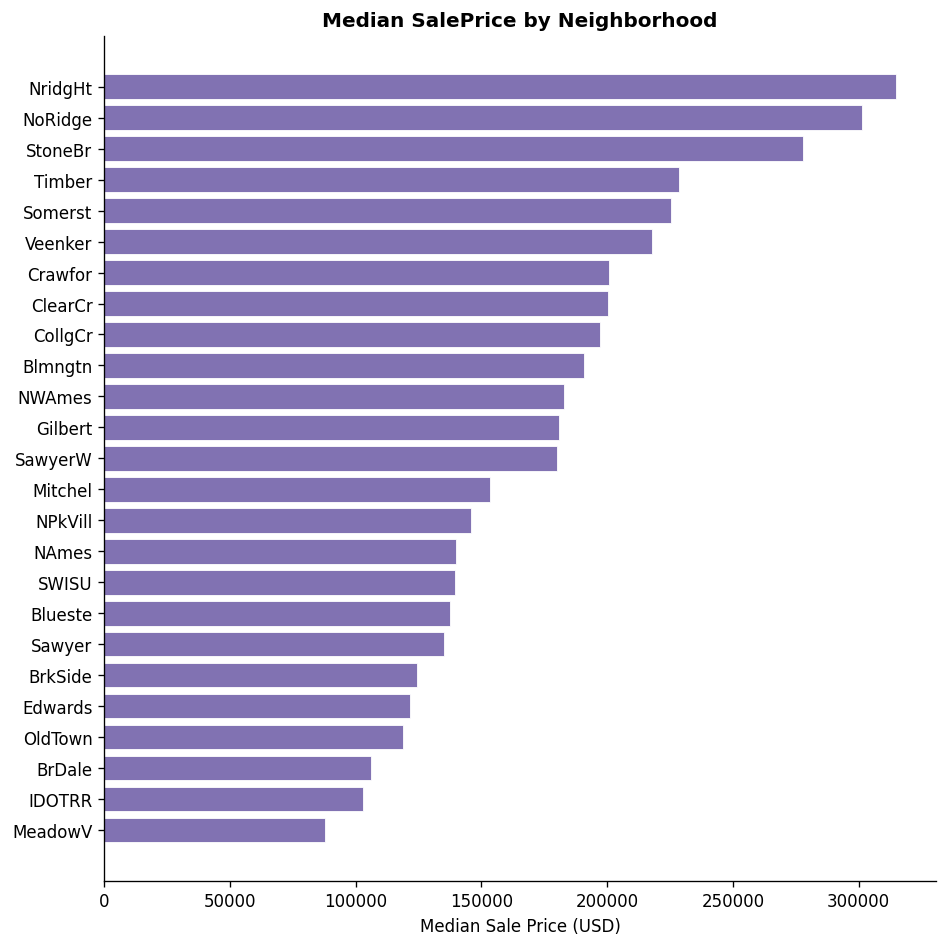

In [11]:
# Neighborhood median prices
nb_med = df.groupby('Neighborhood')['SalePrice'].median().sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(nb_med.index, nb_med.values, color='#8172B2', edgecolor='white', linewidth=0.5)
ax.set_xlabel('Median Sale Price (USD)')
ax.set_title('Median SalePrice by Neighborhood', fontweight='bold')
plt.tight_layout()
plt.show()

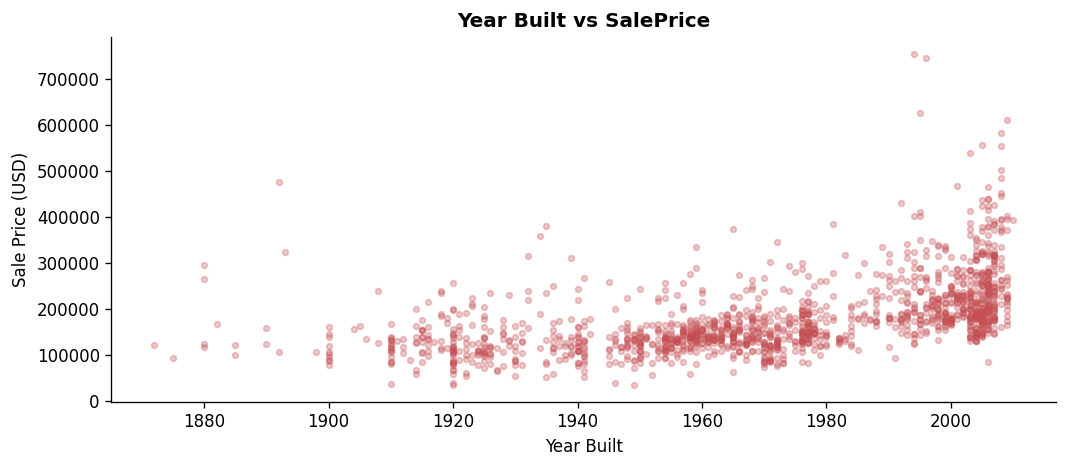

In [12]:
# Year built trend
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(df['YearBuilt'], df['SalePrice'], alpha=0.3, s=12, color='#C44E52')
ax.set_xlabel('Year Built')
ax.set_ylabel('Sale Price (USD)')
ax.set_title('Year Built vs SalePrice', fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Correlation Heatmap — Top Features

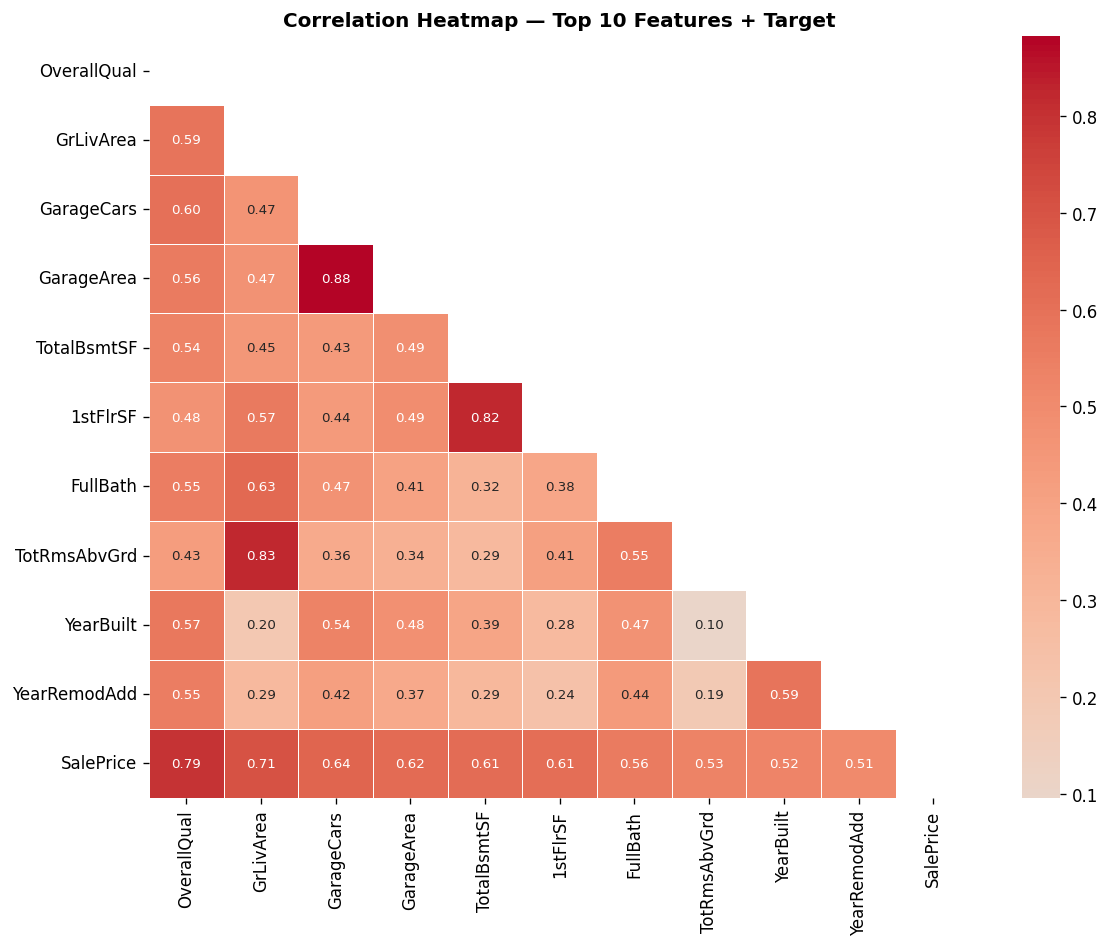

In [13]:
top_feats = corr.abs().nlargest(10).index.tolist() + ['SalePrice']
corr_matrix = df[top_feats].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, ax=ax,
            linewidths=0.5, annot_kws={'size': 8})
ax.set_title('Correlation Heatmap — Top 10 Features + Target', fontweight='bold')
plt.tight_layout()
plt.show()

## 7. EDA Summary

| Finding | Detail |
|---------|--------|
| Target skew | SalePrice is right-skewed → use `log(SalePrice)` as target |
| Strongest predictor | `OverallQual` (quality rating 1–10) |
| Other strong features | `GrLivArea`, `GarageCars`, `TotalBsmtSF`, `1stFlrSF` |
| Missing values | Several features >50% missing — likely mean "no feature" not truly missing |
| Outliers | 2 high-area, low-price homes to investigate before modeling |
| Multicollinearity | `GarageCars` and `GarageArea` are highly correlated — may keep only one |
| Neighborhood | Strong price stratification — important categorical feature |